# ISO 20414:2020 — Test 6: Horizontal counter-flows

Two 10 m x 10 m rooms joined by a 10 m x 2 m corridor (ISO 20414:2020 Table 7). 100 occupants move from room 1 to room 2; the test is repeated with 0, 10, 50 and 100 counter-flow agents moving the other way. The time the last room-1 occupant enters room 2 should increase with counter-flow.

In [1]:
from datetime import datetime
print(f"Executed on {datetime.now().astimezone().strftime('%d %B %Y, %H:%M %Z')}")

Executed on 15 October 2026, 11:01 CEST


In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pedpy
from shapely.geometry import Point, Polygon

from jupedsim_scenarios import load_scenario, run_scenario

In [3]:
plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "#f7f7f5",
    "axes.edgecolor": "#3a3a3a",
    "axes.labelcolor": "#1d1d1d",
    "axes.titleweight": "bold",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
    "figure.figsize": (8, 5),
})

## Scenario check — geometry and trajectories

Before the numerical sweep, confirm the simulated scenario is the ISO Test 6 layout: two 10 m x 10 m rooms joined by a 10 m x 2 m corridor. Using the cf = 10 case, trajectories are coloured by group — the primary crowd flows room 1 -> room 2 (left to right) and the counter-flow agents move room 2 -> room 1 (right to left), meeting in the corridor.

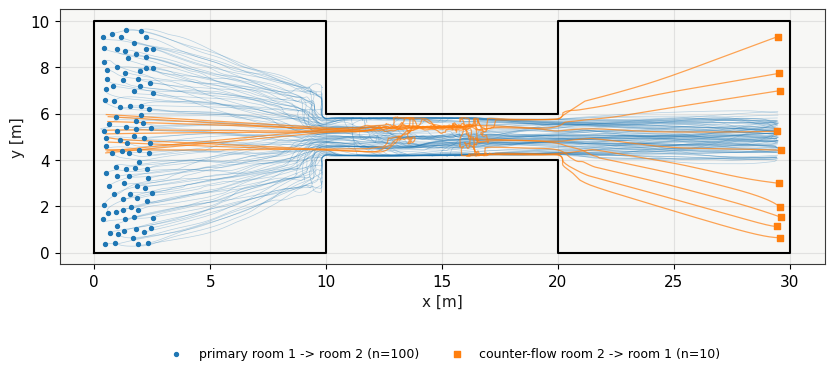

1

In [4]:
check = load_scenario(str(Path('scenario_files') / 'Iso-06-counterflow-10.zip'))
check.max_simulation_time = 400
cr = run_scenario(check, seed=42)
cdf = cr.trajectory_dataframe().sort_values(['id', 'frame'])
starts = cdf.groupby('id').first()
primary_ids = set(starts[starts.x < 5].index)    # start in room 1 -> room 2
counter_ids = set(starts[starts.x > 25].index)   # start in room 2 -> room 1

fig, ax = plt.subplots(figsize=(9, 3.6))
gx, gy = check.walkable_polygon.exterior.xy
ax.plot(gx, gy, 'k-', lw=1.5)
for aid, sub in cdf.groupby('id'):
    if aid in primary_ids:
        ax.plot(sub.x, sub.y, color='tab:blue', alpha=0.3, lw=0.5)
    elif aid in counter_ids:
        ax.plot(sub.x, sub.y, color='tab:orange', alpha=0.7, lw=0.9)
ax.scatter(starts.loc[list(primary_ids)].x, starts.loc[list(primary_ids)].y, s=8,
           color='tab:blue', zorder=3, label=f'primary room 1 -> room 2 (n={len(primary_ids)})')
ax.scatter(starts.loc[list(counter_ids)].x, starts.loc[list(counter_ids)].y, s=20, marker='s',
           color='tab:orange', zorder=3, label=f'counter-flow room 2 -> room 1 (n={len(counter_ids)})')
ax.set_aspect('equal'); ax.set_xlabel('x [m]'); ax.set_ylabel('y [m]')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.28), ncol=2, fontsize=9, frameon=False)
plt.tight_layout(); plt.show()
cr.cleanup()

## Run each counter-flow branch

Room 2 begins at x = 20 m, so a room-1 agent enters it at its first frame with x >= 20. For each counter-flow level we record the time the *last* room-1 agent enters room 2. If any room-1 agent never enters room 2 within the budget, the level is blocked and the time is unbounded; ISO 20414 directs that long-term blocking is documented, not counted as failure.

In [5]:
CF_ZIPS = {0: 'Iso-06-counterflow-0.zip', 10: 'Iso-06-counterflow-10.zip',
           50: 'Iso-06-counterflow-50.zip', 100: 'Iso-06-counterflow-100.zip'}
# One budget for every branch: the unblocked levels finish by about 70 s.
MAX_TIME = 400
ROOM2_X = 20.0

results = []
for cf, zip_name in CF_ZIPS.items():
    scenario = load_scenario(str(Path('scenario_files') / zip_name))
    scenario.max_simulation_time = MAX_TIME
    r = run_scenario(scenario, seed=42)
    df = r.trajectory_dataframe().sort_values(['id', 'frame'])
    first_x = df.groupby('id').first().x
    primary = first_x[first_x < 5.0].index
    entered = df[df.id.isin(primary) & (df.x >= ROOM2_X)].groupby('id').frame.min()
    completed = len(entered) == len(primary)
    results.append({'counterflow': cf, 'primary': len(primary), 'entered_room2': len(entered),
                    'completed': completed,
                    'last_entry_s': float(entered.max() / r.frame_rate) if completed else float('nan')})
    r.cleanup()
transit = pd.DataFrame(results)
for row in transit.itertuples():
    shown = f'{row.last_entry_s:.1f} s' if row.completed else 'blocking documented'
    print(f'counterflow={row.counterflow:>3}: {row.entered_room2:>3}/{row.primary} entered room 2, last entry: {shown}')
transit

counterflow=  0: 100/100 entered room 2, last entry: 46.6 s
counterflow= 10: 100/100 entered room 2, last entry: 70.0 s
counterflow= 50:   1/100 entered room 2, last entry: blocking documented
counterflow=100:   0/100 entered room 2, last entry: blocking documented


,counterflow,primary,entered_room2,completed,last_entry_s
0,0,100,100,True,46.6
1,10,100,100,True,70.0
2,50,100,1,False,NaN
3,100,100,0,False,NaN


## Plot last room-1 entry into room 2 vs counter-flow

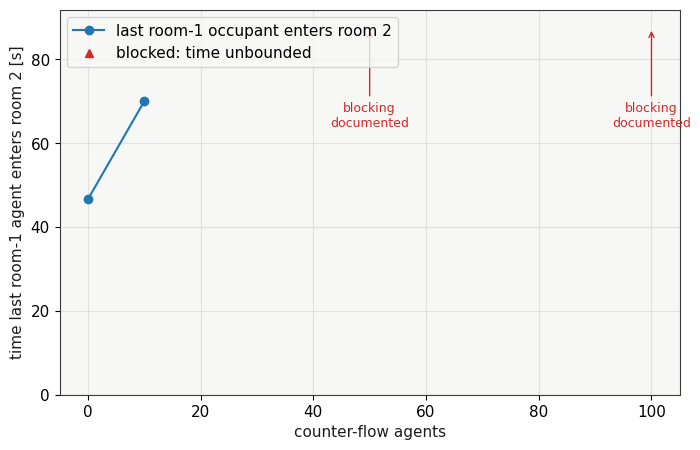

In [6]:
fig, ax = plt.subplots()
cf_levels = transit['counterflow'].to_numpy()
t_last = transit['last_entry_s'].to_numpy()
fin = transit['completed'].to_numpy(dtype=bool)
ax.plot(cf_levels[fin], t_last[fin], 'o-', color='tab:blue', label='last room-1 occupant enters room 2')
top = np.nanmax(t_last) * 1.25
for cf in cf_levels[~fin]:
    ax.annotate('blocking\ndocumented', xy=(cf, top), xytext=(cf, top * 0.8),
                ha='center', va='top', color='tab:red', fontsize=9,
                arrowprops=dict(arrowstyle='->', color='tab:red'))
ax.plot([], [], '^', color='tab:red', label='blocked: time unbounded')
ax.set_ylim(0, top * 1.05)
ax.set_xlim(-5, cf_levels.max() + 5)
ax.set_xlabel('counter-flow agents')
ax.set_ylabel('time last room-1 agent enters room 2 [s]')
ax.legend(loc='upper left')
plt.show()

## Acceptance

ISO 20414:2020 Test 6 expects the time the last room-1 occupant enters room 2 to **increase** with the number of counter-flow occupants, and directs that "if conditions of long-term blocking occur during the simulations, this should be documented". Rule: the 0-counter-flow level must complete; levels where some room-1 agent never enters room 2 within the budget are reported as **blocking documented** (the time is unbounded and blocking is not counted as failure) and count as later than every finite level; the finite times must increase strictly with counter-flow and no finite level may follow a blocked one.

In [7]:
completed = transit['completed'].to_numpy(dtype=bool)
counts = transit['counterflow'].tolist()
times = transit['last_entry_s'].to_numpy()
blocked = [c for c, ok in zip(counts, completed) if not ok]
finite = times[completed]
print('last room-1 entry into room 2 [s]:', dict(zip(counts, np.round(times, 1).tolist())))
print('blocking documented at counterflow level(s):', blocked)
# The 0-counterflow level must complete, otherwise the check below is vacuous.
assert completed[0], transit
# A blocked level counts as later than every finite level: no finite level may follow one.
assert all(completed[: len(finite)]) and not any(completed[len(finite):]), transit
# Finite last-entry times increase strictly with counterflow.
assert (np.diff(finite) > 0).all(), transit
print('RESULT: PASS - ISO 20414:2020 Test 6 (horizontal counter-flows)')

last room-1 entry into room 2 [s]: {0: 46.6, 10: 70.0, 50: nan, 100: nan}
blocking documented at counterflow level(s): [50, 100]
RESULT: PASS - ISO 20414:2020 Test 6 (horizontal counter-flows)
